# Trabajo 2 - Latencia y fallas de MINION en FiQA-2018

Paper: *MINION: Parallel Hybrid Retrieval and Reranking under a Latency Budget*. Todos los numeros de este cuaderno se calculan a partir de los archivos de `results/`; ningun valor esta escrito a mano en el texto.

## 1. Objetivo

Responder la parte de latencia y continuidad del paper: (i) p99 de extremo a extremo <= SLO bajo carga hasta 100 % de la capacidad C; (iii) continuidad >= 99 % cuando el reranker falla o se demora (rutas de la Tabla 2); (iv) solicitudes duplicadas (hedging) <= 10 %. La calidad (P@3, fitness ii) se calcula en el Trabajo 1.

In [1]:
import sys, json
from IPython.display import Markdown, display
import pandas as pd
sys.path.insert(0, '.')
from analysis_lib import Run
R = Run('fiqa', root='results', figs='figs')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

## 2. Montaje

Hardware y versiones leidos de `run_meta.json`.

In [2]:
hw = R.hardware()
for k, v in hw.items():
    print(f'{k}: {v}')

gpu: Tesla T4
device: cuda
nvidia-smi: ['| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |', '| N/A   36C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |', '| N/A   51C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |']
cpu_model: Intel(R) Xeon(R) CPU @ 2.00GHz
cpus: 4
node: def1b12b6c31
python: 3.13.16
libraries: {'torch': '2.11.0+cu130', 'sentence-transformers': '6.3.0', 'transformers': '5.20.2', 'faiss-cpu': '1.16.0', 'bm25s': '0.3.16', 'PyStemmer': '3.1.0', 'numpy': '2.1.3', 'scipy': '1.16.3', 'huggingface-hub': '1.33.0', 'tokenizers': '0.23.3'}
script_sha256: 36671cd85f4b168d422c916701bbec79ec90bd7edb7f0d65ea36e52e9a9f0f47
corpus_size: 57638
n_test_queries: 648
n_calibration_queries: 5500
pilot: False
phase0_seconds: 277.5


Arquitectura (se imprime desde la configuracion congelada guardada en `run_meta.json`):

In [3]:
cfg = R.meta['config']; to = cfg['timeouts_ms']
print(f"""
generador de carga (Poisson, open-loop, semilla {cfg['seed']})
  consulta(q):
    lex, sem = gather(wait_for(bm25s, {to['lexical']} ms), wait_for({cfg['semantic']['model']}, {to['semantic']} ms))
    candidatos = union (<= 2 x {cfg['lexical']['top_k']}) -> min-max por consulta -> fusion alpha={R.meta['alpha_json']['alpha']} (wait_for {to['fusion']} ms)
    top3 = rerank_con_hedging({cfg['reranker']['model']}, {cfg['reranker']['replicas']} replicas, plazo {to['rerank']} ms)
    ruta segun la Tabla 2 (SLO {cfg['slo_ms']} ms)
""")


generador de carga (Poisson, open-loop, semilla 42)
  consulta(q):
    lex, sem = gather(wait_for(bm25s, 50 ms), wait_for(BAAI/bge-base-en-v1.5, 1200 ms))
    candidatos = union (<= 2 x 10) -> min-max por consulta -> fusion alpha=0.85 (wait_for 50 ms)
    top3 = rerank_con_hedging(cross-encoder/ms-marco-MiniLM-L-6-v2, 2 replicas, plazo 1200 ms)
    ruta segun la Tabla 2 (SLO 2500 ms)



Condiciones: `L25-L100` = sistema completo con hedging sin fallas al 25/50/75/100 % de C; `NORERANK` = linea base que no invoca el reranker; `NOHEDGE` = 100 % de C sin hedging; `F1`/`F2` = reranker con error o con demora de 1500 ms en ambas replicas; `F3H`/`F3NH` = demora de 800 ms con p=0.05 en la replica A, con y sin hedging, con llegadas y demoras identicas; `F4`/`F5`/`F6` = fallas de la busqueda semantica, lexica o ambas.

In [4]:
pd.DataFrame(R.meta['settings'].items(), columns=['setting', 'value'])

,setting,value
0,max_docs,None
1,cond_seconds,180
2,warmup_seconds,30
3,ramp_seconds,120
4,calib_n,500
5,ramp_rates,"[1, 2, 4, 8, 16, 32, 64]"
6,reps,3
7,conditions,"[L25, L50, L75, L100, NORERANK, NOHEDGE, F1, F..."


## 3. Calibracion

K1: rampa de carga (C = mayor tasa con throughput >= 99 % de lo enviado y p99 estable). K2: latencia por etapa a 1 QPS.

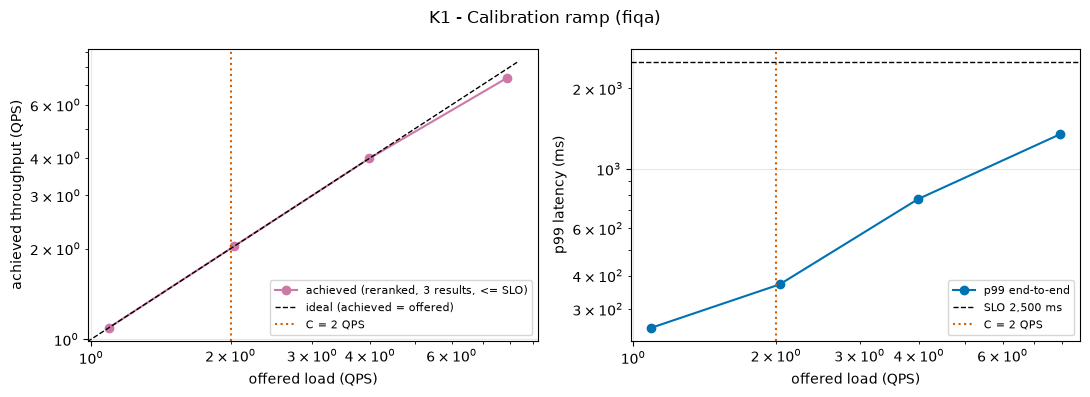

In [5]:
R.k1()

In [6]:
R.ramp_table()

,rate,n_sent,qps_offered_measured,qps_achieved,throughput_ratio,p99_ms,p99_first_half_ms,p99_second_half_ms,p99_stable,pass
0,1,131,1.092,1.092,1.000,255.348,255.348,271.531,True,True
1,2,244,2.033,2.033,1.000,370.462,435.500,340.638,True,True
2,4,478,3.983,3.983,1.000,772.077,570.937,811.678,False,False
3,8,949,7.908,7.375,0.933,1344.360,1344.360,1356.158,True,False


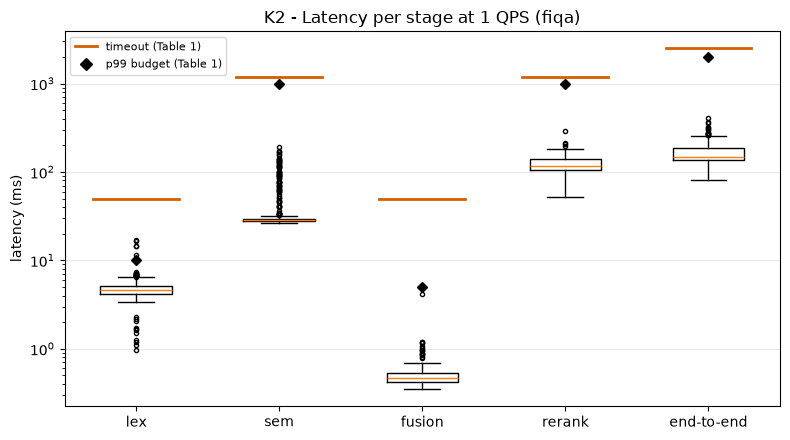

In [7]:
R.k2()

In [8]:
R.stage_table()

,stage,n,p50_ms,p95_ms,p99_ms,table1_budget_p99_ms,table1_timeout_ms
0,lex,500,4.67,6.34,7.42,10,50
1,sem,500,28.31,99.66,155.50,1000,1200
2,fusion,500,0.47,0.63,1.02,5,50
3,rerank,500,115.37,168.07,177.04,1000,1200
4,e2e,500,149.14,228.19,305.39,2000,2500


In [9]:
display(Markdown(f"**C = {R.C} QPS**; umbral de hedging = p95 del reranker = "
                 f"**{R.cal['hedge_threshold_ms']:.1f} ms**."))

**C = 2 QPS**; umbral de hedging = p95 del reranker = **168.1 ms**.

## 4. Carga

K3: ECDF; K4: percentiles vs carga; K5: serie temporal en L100 y F2.

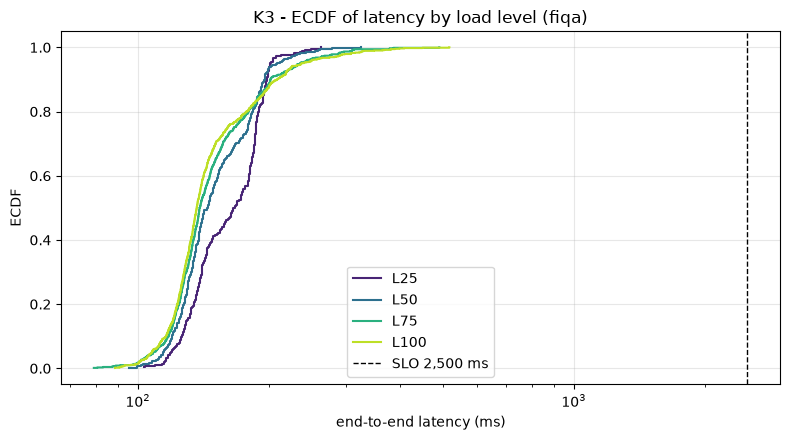

In [10]:
R.k3()

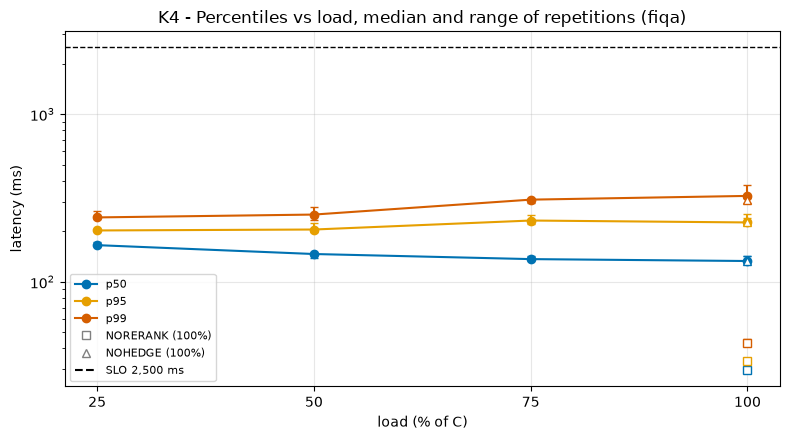

In [11]:
R.k4()

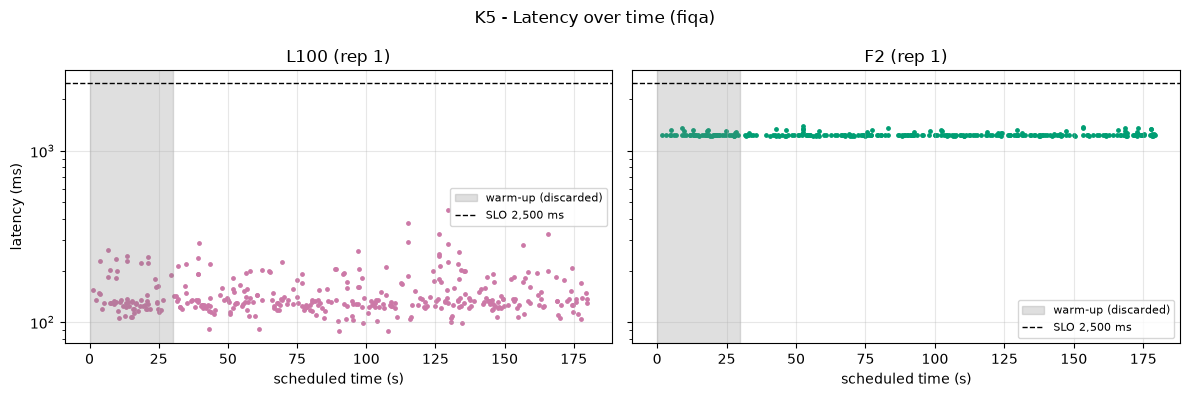

In [12]:
R.k5()

In [13]:
R.percentile_table()

,condition,load_pct,qps_offered,p50_ms,p95_ms,p99_ms
0,L25,25,0.5,165.4 [163.3-172.0],202.4 [199.9-204.5],242.1 [235.7-263.0]
1,L50,50,1.0,146.4 [138.3-146.8],205.0 [199.3-224.2],251.7 [233.7-278.6]
2,L75,75,1.5,136.5 [135.9-142.8],231.9 [221.3-249.6],309.0 [296.5-313.5]
3,L100,100,2.0,133.0 [132.5-141.8],225.9 [219.4-252.5],325.3 [314.7-379.4]
4,NORERANK,100,2.0,29.7 [29.6-29.9],33.8 [33.7-35.1],43.3 [42.2-45.3]
5,NOHEDGE,100,2.0,132.8 [131.8-141.8],227.2 [222.0-240.9],306.6 [295.7-315.3]
6,F1,75,1.5,30.0 [29.8-30.1],33.8 [33.7-34.3],45.0 [38.4-50.1]
7,F2,75,1.5,1231.1 [1230.8-1231.2],1322.8 [1318.3-1327.4],1368.0 [1364.5-1379.8]
8,F3H,75,1.5,137.5 [135.7-141.7],300.5 [265.0-316.4],389.5 [312.0-449.9]
9,F3NH,75,1.5,142.8 [135.2-144.1],316.8 [227.5-881.2],947.6 [930.7-988.9]


## 5. Fallas

K6: matriz de rutas; K7: continuidad. La tabla compara la ruta esperada por la Tabla 2 con la observada.

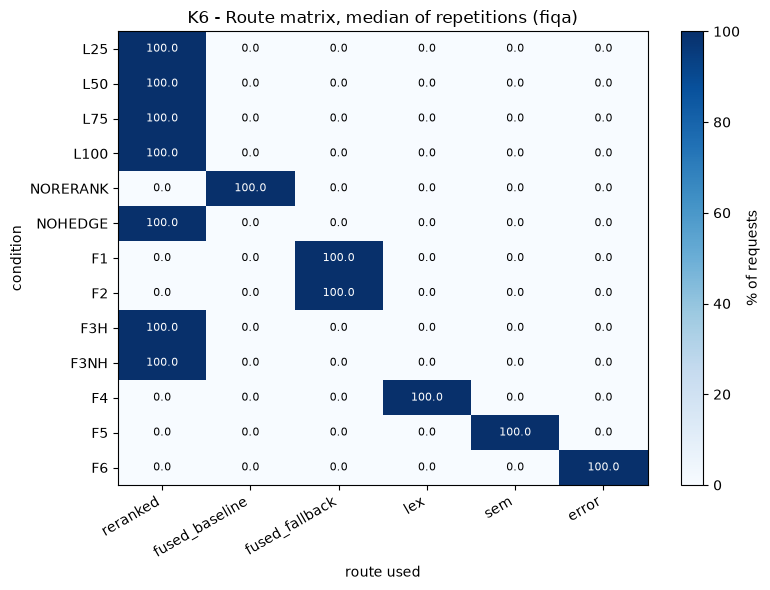

In [14]:
R.k6()

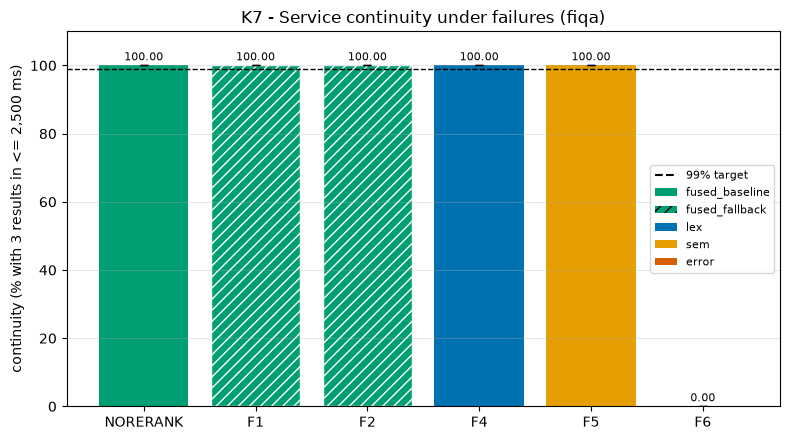

In [15]:
R.k7()

In [16]:
R.routes_table()

,condition,expected_route,observed_route,observed_pct,match,others_pct
0,L25,reranked,reranked,100.0,True,0.0
1,L50,reranked,reranked,100.0,True,0.0
2,L75,reranked,reranked,100.0,True,0.0
3,L100,reranked,reranked,100.0,True,0.0
4,NORERANK,fused_baseline,fused_baseline,100.0,True,0.0
5,NOHEDGE,reranked,reranked,100.0,True,0.0
6,F1,fused_fallback,fused_fallback,100.0,True,0.0
7,F2,fused_fallback,fused_fallback,100.0,True,0.0
8,F3H,reranked,reranked,100.0,True,0.0
9,F3NH,reranked,reranked,100.0,True,0.0


## 6. Hedging

F3H y F3NH reciben las mismas llegadas y demoran las mismas solicitudes; la diferencia se debe solo a duplicar.

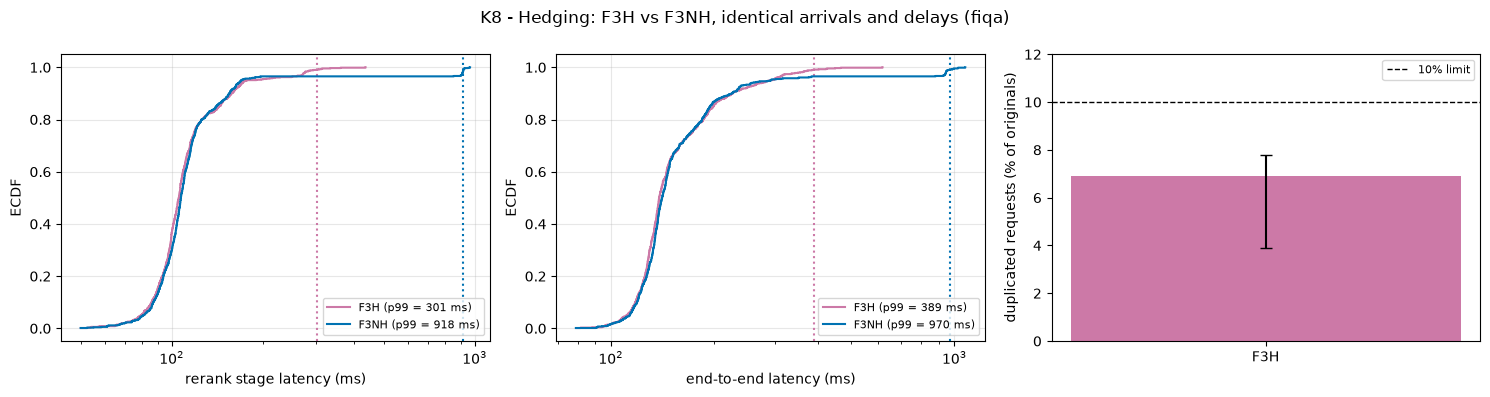

In [17]:
R.k8()

In [18]:
t, diff = R.hedging_table()
display(t)
print({k: round(v, 2) for k, v in diff.items()}, '<- F3NH menos F3H (ms)')

,rerank_p99_ms,e2e_p99_ms,dup_pct,rerank_p99_per_rep,e2e_p99_per_rep
F3H,305.741,389.485,6.9264,"[271.2, 305.7, 311.6]","[312.0, 389.5, 449.9]"
F3NH,917.497,947.583,0.0,"[900.7, 920.6, 917.5]","[930.7, 988.9, 947.6]"


{'rerank_p99_ms': np.float64(611.76), 'e2e_p99_ms': 558.1} <- F3NH menos F3H (ms)


## 7. Fitness functions

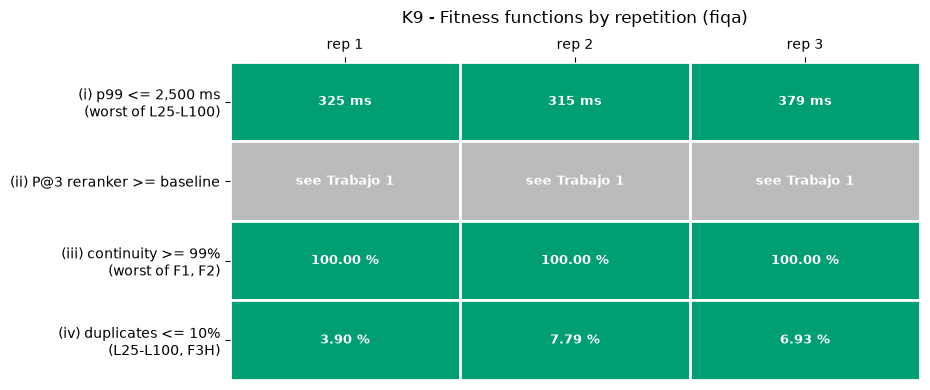

In [19]:
R.k9()

In [20]:
R.fitness_table()

,fitness,worst_value,threshold,meets,margin
0,"(i) p99 <= 2500 ms, L25-L100",379.4 ms,2500 ms,True,2120.6 ms
1,(ii) P@3 with reranker >= without,see Trabajo 1,-,None,-
2,(iii) continuity >= 99% in F1 and F2,100.00 %,99 %,True,1.00 pp
3,(iv) duplicates <= 10% in L25-L100 and F3H,7.79 %,10 %,True,2.21 pp


## 8. Limitaciones

- Las dos replicas del reranker son dos instancias del modelo en la misma GPU.
- Todo corre en un solo proceso (`asyncio` + hilos) y en una sola maquina (sesion de Kaggle, no Khipu).
- El hardware y las latencias absolutas dependen de la GPU de la sesion; C se calibra en la misma maquina.
- Con pocas solicitudes por condicion el p99 equivale a un valor cercano al maximo.

## 9. Conclusion

In [21]:
display(Markdown('\n'.join('- ' + b for b in R.conclusions())))

- Measured capacity C = 2 QPS; hedging threshold = 168.1 ms (p95 of the reranker at 1 QPS).
- At 100% of C the end-to-end p99 is 325.3 ms (range 314.7-379.4) against the 2500 ms SLO; fitness (i) is met in 3/3 repetitions.
- Skipping the reranker (NORERANK) gives p99 = 43.3 ms, so the reranker adds about 282.0 ms at the 99th percentile.
- Continuity with the reranker failing (F1) or slow (F2): 100.00% and 100.00%; fitness (iii) is met.
- Search failures: continuity is 100.00% without the semantic search (F4) and 100.00% without the lexical search (F5); with both failing (F6) it is 0.00%, the controlled error expected by Table 2.
- 13/13 conditions used exactly the route predicted by Table 2.
- Hedging changes the p99 of the reranking stage by 611.8 ms and the end-to-end p99 by 558.1 ms (F3NH minus F3H), with 6.93% duplicated requests; fitness (iv) is met.
- Fitness (ii), the relevance of the reranked top 3, is evaluated in Trabajo 1 and is not measured here.